# Static Phase reading
Imports a file produced during a static phase. The file can be specified in a dialog box.

Dugr, 2026-10-26

In [1]:
import json
import pandas as pd
from matplotlib import pyplot as plt
import tkinter as tk
from tkinter import filedialog


{'id': '20261026110939Z',
 'date': '2026-10-26 12:09:50',
 'user': 'gregor.dudle',
 'KibbleBalanceModel': 'StaticPhaseM03',
 'WeightDriver': {'period': 20,
  'amplitude': 9.81,
  'rising': 0.2,
  'width': 9.8,
  'falling': 0.2},
 'PID': {'k': 0.1, 'Td': 1, 'Ti': 1},
 'Simulation': {'startTime': 0.0,
  'stopTime': 100.0,
  'numberOfIntervals': 1000,
  'tolerance': 1e-06,
  'method': 'dassl',
  'fileNamePrefix': 'StaticPhaseM03',
  'options': '',
  'outputFormat': 'csv',
  'variableFilter': '.*',
  'cflags': '',
  'simflags': '-override=Driver.period=20,Driver.amplitude=9.81,Driver.rising=0.2,Driver.width=9.8,Driver.falling=0.2,PID.k=0.1,PID.Td=1,PID.Ti=1'}}

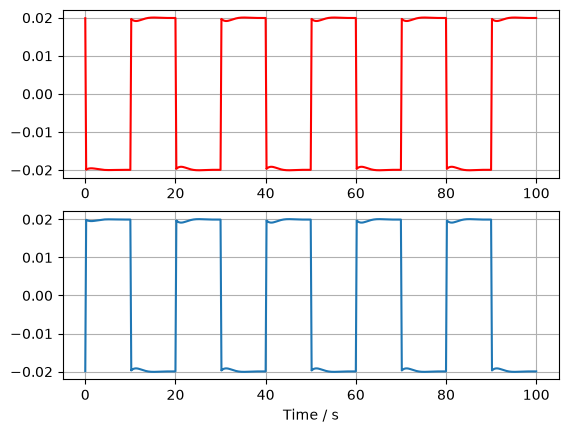

In [2]:
window = tk.Tk()
window.wm_attributes('-topmost', 1)
window.withdraw()   # this supress the tk window
filename = filedialog.askopenfilename(parent=window)

with open(filename) as f:
    data_meta = json.load(f)
    f.close()
if data_meta["metadata"]["KibbleBalanceModel"][0:11] != "StaticPhase":
    print("Error: This script is only for StaticPhase model results")
else:
    df = pd.DataFrame()

    display(data_meta["metadata"])
    data = pd.DataFrame(data_meta["data"])
    
    fig,ax = plt.subplots(2)
    #ax[0].plot(data["time"],data["B_l"])

    ax[0].plot(data["time"],data["coil.p.i"],"r")
    ax[0].grid()
    ax[1].plot(data["time"],data["coil.n.i"])
    ax[1].grid()
    ax[1].set_xlabel("Time / s")
